# Knowledge Graph Recommender

## Project
An Explainable Knowledge Graph-Driven Hybrid Recommender for Intelligent Task Allocation in Distributed Onboarding Operations

## Purpose

This notebook develops the knowledge graph component of the intelligent task allocation recommender.

The knowledge graph represents important entities and relationships within the task allocation environment.

The graph includes:

- Onboarding agents
- Tasks
- Skills
- Locations
- Agent-skill relationships
- Task-skill requirements
- Agent and task locations
- Historical task assignments

The graph will be used to identify meaningful relationships between agents and tasks and to produce explainable graph-based recommendation scores.

The current experiment uses synthetic development data while awaiting the approved industry dataset. Results are therefore treated as development evidence rather than final real-world performance.

## Experiment Information

- Run ID: KG_RUN_001
- Model: Knowledge Graph Recommender
- Graph Library: NetworkX
- Dataset Version: Synthetic Development Dataset v1
- Random Seed: 42
- Training Split: 70%
- Validation Split: 15%
- Test Split: 15%
- Test data will remain separate during development

In [2]:
import pandas as pd
import numpy as np
import networkx as nx

from pathlib import Path

In [3]:
RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)

project_root = Path.cwd().parent

raw_data_path = project_root / "data" / "raw"
processed_data_path = project_root / "data" / "processed"

print("Project root:", project_root)

Project root: c:\Users\sagoo\OneDrive - Strathmore University\YEAR 4\SEM 1\IS Project II\intelligent-task-allocation


In [4]:
agents_df = pd.read_csv(
    raw_data_path / "agents.csv"
)

skills_df = pd.read_csv(
    raw_data_path / "skills.csv"
)

agent_skills_df = pd.read_csv(
    raw_data_path / "agent_skills.csv"
)

tasks_df = pd.read_csv(
    raw_data_path / "tasks.csv"
)

task_skills_df = pd.read_csv(
    raw_data_path / "task_skills.csv"
)

train_df = pd.read_csv(
    processed_data_path / "train_interactions.csv"
)

validation_df = pd.read_csv(
    processed_data_path / "validation_interactions.csv"
)

test_df = pd.read_csv(
    processed_data_path / "test_interactions.csv"
)

print("Agents:", len(agents_df))
print("Skills:", len(skills_df))
print("Tasks:", len(tasks_df))
print("Training interactions:", len(train_df))
print("Validation interactions:", len(validation_df))
print("Test interactions:", len(test_df))

Agents: 100
Skills: 8
Tasks: 2000
Training interactions: 912
Validation interactions: 196
Test interactions: 196


## 3. Construct the Knowledge Graph

The task allocation domain is represented as a directed knowledge graph.

The graph contains four main entity types:

- Agent
- Task
- Skill
- Location

The main relationships are:

- Agent `HAS_SKILL` Skill
- Task `REQUIRES_SKILL` Skill
- Agent `LOCATED_IN` Location
- Task `LOCATED_IN` Location
- Agent `COMPLETED_TASK` Task

Historical task completion relationships are created using training interactions only. Validation and test outcomes are not included in the graph during development to prevent data leakage.

In [5]:
G = nx.DiGraph()

print("Empty graph created.")

Empty graph created.


### 3.1 Add Agent Nodes

Each onboarding agent is represented as a graph node with attributes describing their profile.

In [6]:
for _, agent in agents_df.iterrows():

    node_id = f"agent:{agent['agent_id']}"

    G.add_node(
        node_id,
        node_type="Agent",
        agent_id=agent["agent_id"],
        name=agent["name"],
        specialization=agent["specialization"],
        availability=bool(agent["availability"]),
        workload=int(agent["workload"]),
        performance_score=float(agent["performance_score"]),
        experience_years=int(agent["experience_years"])
    )

print(
    "Agent nodes added:",
    sum(
        1
        for _, data in G.nodes(data=True)
        if data.get("node_type") == "Agent"
    )
)

Agent nodes added: 100


### 3.2 Add Skill Nodes

In [7]:
for _, skill in skills_df.iterrows():

    node_id = f"skill:{skill['skill_id']}"

    G.add_node(
        node_id,
        node_type="Skill",
        skill_id=skill["skill_id"],
        skill_name=skill["skill_name"]
    )

print(
    "Skill nodes added:",
    sum(
        1
        for _, data in G.nodes(data=True)
        if data.get("node_type") == "Skill"
    )
)

Skill nodes added: 8


### 3.3 Add Task Nodes

In [8]:
for _, task in tasks_df.iterrows():

    node_id = f"task:{task['task_id']}"

    G.add_node(
        node_id,
        node_type="Task",
        task_id=task["task_id"],
        task_type=task["task_type"],
        priority=task["priority"],
        difficulty=task["difficulty"],
        status=task["status"]
    )

print(
    "Task nodes added:",
    sum(
        1
        for _, data in G.nodes(data=True)
        if data.get("node_type") == "Task"
    )
)

Task nodes added: 2000


### 3.4 Add Location Nodes

Locations are represented as separate graph entities so that agents and tasks can be connected through geographic relationships.

In [9]:
locations = sorted(
    set(agents_df["location"])
    | set(tasks_df["location"])
)

for location in locations:

    node_id = f"location:{location}"

    G.add_node(
        node_id,
        node_type="Location",
        location_name=location
    )

print(
    "Location nodes added:",
    len(locations)
)

print(locations)

Location nodes added: 6
['Eldoret', 'Kisumu', 'Mombasa', 'Nairobi', 'Nakuru', 'Thika']


## 4. Add Knowledge Graph Relationships

Relationships connect the graph entities and represent the information used for task allocation reasoning.

In [10]:
for _, row in agent_skills_df.iterrows():

    agent_node = f"agent:{row['agent_id']}"
    skill_node = f"skill:{row['skill_id']}"

    G.add_edge(
        agent_node,
        skill_node,
        relation="HAS_SKILL",
        proficiency_level=row["proficiency_level"]
    )

In [11]:
for _, row in task_skills_df.iterrows():

    task_node = f"task:{row['task_id']}"
    skill_node = f"skill:{row['skill_id']}"

    G.add_edge(
        task_node,
        skill_node,
        relation="REQUIRES_SKILL",
        required_level=row["required_level"]
    )

In [12]:
for _, agent in agents_df.iterrows():

    agent_node = f"agent:{agent['agent_id']}"
    location_node = f"location:{agent['location']}"

    G.add_edge(
        agent_node,
        location_node,
        relation="LOCATED_IN"
    )

In [14]:
for _, task in tasks_df.iterrows():

    task_node = f"task:{task['task_id']}"
    location_node = f"location:{task['location']}"

    G.add_edge(
        task_node,
        location_node,
        relation="LOCATED_IN"
    )

In [15]:
for _, interaction in train_df.iterrows():

    agent_node = f"agent:{interaction['agent_id']}"
    task_node = f"task:{interaction['task_id']}"

    G.add_edge(
        agent_node,
        task_node,
        relation="COMPLETED_TASK",
        performance_rating=float(
            interaction["performance_rating"]
        )
    )

## 5. Inspect the Knowledge Graph

The graph structure is inspected to confirm that the expected entities and relationships were created successfully.

In [16]:
print("Total nodes:", G.number_of_nodes())
print("Total edges:", G.number_of_edges())

node_type_counts = {}

for _, data in G.nodes(data=True):

    node_type = data.get(
        "node_type",
        "Unknown"
    )

    node_type_counts[node_type] = (
        node_type_counts.get(node_type, 0) + 1
    )

print("\nNodes by type:")

for node_type, count in node_type_counts.items():
    print(node_type, ":", count)

Total nodes: 2114
Total edges: 7197

Nodes by type:
Agent : 100
Skill : 8
Task : 2000
Location : 6


In [17]:
relation_counts = {}

for _, _, data in G.edges(data=True):

    relation = data.get(
        "relation",
        "Unknown"
    )

    relation_counts[relation] = (
        relation_counts.get(relation, 0) + 1
    )

print("Relationships by type:")

for relation, count in relation_counts.items():
    print(relation, ":", count)

Relationships by type:
HAS_SKILL : 298
LOCATED_IN : 2100
COMPLETED_TASK : 912
REQUIRES_SKILL : 3887


### Interpretation

The knowledge graph was successfully constructed using agent, task, skill and location entities.

Agent capabilities are represented through `HAS_SKILL` relationships, while task requirements are represented through `REQUIRES_SKILL` relationships.

Geographic information is represented using `LOCATED_IN` relationships.

Historical allocation evidence is represented using `COMPLETED_TASK` relationships created from training interactions only.

Validation and test outcomes were excluded from graph construction to prevent evaluation data leakage.

The graph can now be used to identify meaningful paths between agents and tasks and calculate graph-based recommendation scores.

## 6. Visualize a Knowledge Graph Subgraph

The complete knowledge graph contains thousands of nodes and relationships, making a full visualization difficult to interpret.

A smaller subgraph is therefore visualized around one example onboarding task.

The visualization shows the selected task together with its required skills, location, relevant agents and historical task relationship.

In [18]:
import matplotlib.pyplot as plt

# Select a task that exists in the training interactions
sample_graph_task_id = train_df.iloc[0]["task_id"]

task_node = f"task:{sample_graph_task_id}"

nodes_to_show = {task_node}


# --------------------------------------------------
# Get task skills and location
# --------------------------------------------------

task_neighbors = list(
    G.successors(task_node)
)

task_skills = [
    node
    for node in task_neighbors
    if G.nodes[node].get("node_type") == "Skill"
]

task_locations = [
    node
    for node in task_neighbors
    if G.nodes[node].get("node_type") == "Location"
]

nodes_to_show.update(task_skills)
nodes_to_show.update(task_locations)


# --------------------------------------------------
# Find agents connected to the required skills
# --------------------------------------------------

candidate_agents = set()

for skill_node in task_skills:

    for node in G.predecessors(skill_node):

        if G.nodes[node].get("node_type") == "Agent":
            candidate_agents.add(node)


# Limit the number of agents shown
candidate_agents = sorted(
    candidate_agents
)[:8]

nodes_to_show.update(candidate_agents)


# --------------------------------------------------
# Include the historically assigned agent
# --------------------------------------------------

historical_agents = [
    node
    for node in G.predecessors(task_node)
    if G.nodes[node].get("node_type") == "Agent"
]

nodes_to_show.update(historical_agents)


# --------------------------------------------------
# Create smaller graph
# --------------------------------------------------

subgraph = G.subgraph(
    nodes_to_show
).copy()

print(
    "Visualized task:",
    sample_graph_task_id
)

print(
    "Subgraph nodes:",
    subgraph.number_of_nodes()
)

print(
    "Subgraph edges:",
    subgraph.number_of_edges()
)

Matplotlib is building the font cache; this may take a moment.


Visualized task: T1471
Subgraph nodes: 12
Subgraph edges: 14


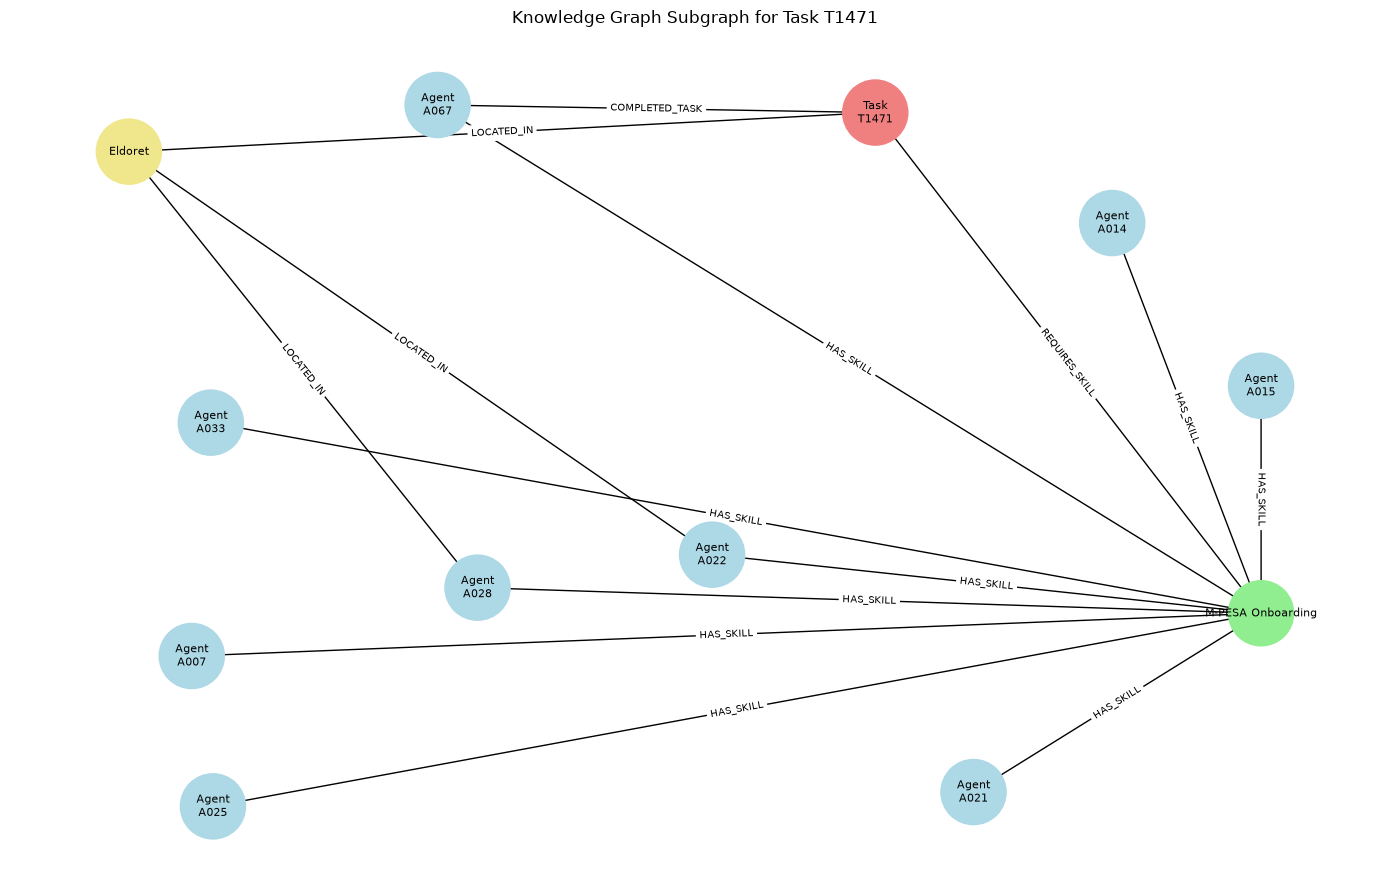

In [19]:
plt.figure(
    figsize=(14, 9)
)

position = nx.spring_layout(
    subgraph,
    seed=42,
    k=1.5
)


# Assign a colour according to entity type
node_colors = []

for node in subgraph.nodes():

    node_type = G.nodes[node].get(
        "node_type"
    )

    if node_type == "Agent":
        node_colors.append("lightblue")

    elif node_type == "Task":
        node_colors.append("lightcoral")

    elif node_type == "Skill":
        node_colors.append("lightgreen")

    elif node_type == "Location":
        node_colors.append("khaki")

    else:
        node_colors.append("lightgray")


# Create readable labels
labels = {}

for node in subgraph.nodes():

    node_data = G.nodes[node]

    node_type = node_data.get(
        "node_type"
    )

    if node_type == "Agent":

        labels[node] = (
            "Agent\n"
            + node_data["agent_id"]
        )

    elif node_type == "Task":

        labels[node] = (
            "Task\n"
            + node_data["task_id"]
        )

    elif node_type == "Skill":

        labels[node] = (
            node_data["skill_name"]
        )

    elif node_type == "Location":

        labels[node] = (
            node_data["location_name"]
        )


# Draw nodes
nx.draw_networkx_nodes(
    subgraph,
    position,
    node_color=node_colors,
    node_size=2200
)


# Draw edges
nx.draw_networkx_edges(
    subgraph,
    position,
    arrows=True,
    arrowsize=20
)


# Draw labels
nx.draw_networkx_labels(
    subgraph,
    position,
    labels=labels,
    font_size=8
)


# Relationship labels
edge_labels = {
    (source, target):
        data.get("relation", "")
    for source, target, data
    in subgraph.edges(data=True)
}

nx.draw_networkx_edge_labels(
    subgraph,
    position,
    edge_labels=edge_labels,
    font_size=7
)


plt.title(
    f"Knowledge Graph Subgraph for Task {sample_graph_task_id}"
)

plt.axis("off")

plt.tight_layout()

plt.show()

## 7. Calculate Knowledge Graph Suitability

The knowledge graph is used to measure how strongly an agent is connected to the requirements of a task.

The graph-based score considers:

- Shared skill relationships between an agent and a task
- Whether the agent's skill proficiency meets the task requirement
- Shared location relationships
- Previous completion of the same type of onboarding task
- Historical performance on similar tasks

Only historical completion relationships from the training dataset are used.

In [20]:
proficiency_map = {
    "Beginner": 1,
    "Intermediate": 2,
    "Advanced": 3
}

KG_WEIGHTS = {
    "skill_relation": 0.50,
    "location_relation": 0.15,
    "historical_task_type": 0.20,
    "historical_performance": 0.15
}

print(
    "Total KG weight:",
    sum(KG_WEIGHTS.values())
)

Total KG weight: 1.0


In [21]:
def calculate_kg_features(
    agent_id,
    task_id
):

    agent_node = f"agent:{agent_id}"
    task_node = f"task:{task_id}"

    agent_data = G.nodes[agent_node]
    task_data = G.nodes[task_node]

    # --------------------------------------------------
    # 1. Skill relationship score
    # --------------------------------------------------

    required_skills = {}

    for neighbor in G.successors(task_node):

        edge = G[task_node][neighbor]

        if edge.get("relation") == "REQUIRES_SKILL":

            required_skills[neighbor] = (
                proficiency_map[
                    edge["required_level"]
                ]
            )

    matched_skill_scores = []

    for skill_node, required_level in required_skills.items():

        if G.has_edge(
            agent_node,
            skill_node
        ):

            agent_edge = G[
                agent_node
            ][skill_node]

            if (
                agent_edge.get("relation")
                == "HAS_SKILL"
            ):

                agent_level = (
                    proficiency_map[
                        agent_edge[
                            "proficiency_level"
                        ]
                    ]
                )

                matched_skill_scores.append(
                    min(
                        agent_level
                        / required_level,
                        1.0
                    )
                )

            else:
                matched_skill_scores.append(0.0)

        else:
            matched_skill_scores.append(0.0)

    if required_skills:

        skill_relation_score = (
            sum(matched_skill_scores)
            / len(required_skills)
        )

    else:
        skill_relation_score = 0.0


    # --------------------------------------------------
    # 2. Shared location relationship
    # --------------------------------------------------

    agent_locations = {
        node
        for node in G.successors(agent_node)
        if G[
            agent_node
        ][node].get("relation")
        == "LOCATED_IN"
    }

    task_locations = {
        node
        for node in G.successors(task_node)
        if G[
            task_node
        ][node].get("relation")
        == "LOCATED_IN"
    }

    location_relation_score = (
        1.0
        if agent_locations
        & task_locations
        else 0.0
    )


    # --------------------------------------------------
    # 3. Historical task-type relationships
    # --------------------------------------------------

    target_task_type = task_data[
        "task_type"
    ]

    historical_ratings = []

    for completed_task_node in G.successors(
        agent_node
    ):

        edge = G[
            agent_node
        ][completed_task_node]

        if (
            edge.get("relation")
            == "COMPLETED_TASK"
        ):

            completed_task_type = (
                G.nodes[
                    completed_task_node
                ].get("task_type")
            )

            if (
                completed_task_type
                == target_task_type
            ):

                historical_ratings.append(
                    float(
                        edge[
                            "performance_rating"
                        ]
                    )
                )

    historical_task_type_score = (
        1.0
        if historical_ratings
        else 0.0
    )

    if historical_ratings:

        historical_performance_score = (
            np.mean(
                historical_ratings
            ) / 5.0
        )

    else:
        historical_performance_score = 0.0


    return {
        "skill_relation_score":
            round(
                float(
                    skill_relation_score
                ),
                4
            ),

        "location_relation_score":
            location_relation_score,

        "historical_task_type_score":
            historical_task_type_score,

        "historical_performance_score":
            round(
                float(
                    historical_performance_score
                ),
                4
            ),

        "historical_matches":
            len(historical_ratings)
    }

In [22]:
def calculate_kg_score(
    agent_id,
    task_id
):

    agent_node = f"agent:{agent_id}"

    agent = G.nodes[
        agent_node
    ]

    # Operational constraint
    if not bool(
        agent["availability"]
    ):
        return None

    features = calculate_kg_features(
        agent_id,
        task_id
    )

    total_score = (
        KG_WEIGHTS[
            "skill_relation"
        ]
        * features[
            "skill_relation_score"
        ]

        + KG_WEIGHTS[
            "location_relation"
        ]
        * features[
            "location_relation_score"
        ]

        + KG_WEIGHTS[
            "historical_task_type"
        ]
        * features[
            "historical_task_type_score"
        ]

        + KG_WEIGHTS[
            "historical_performance"
        ]
        * features[
            "historical_performance_score"
        ]
    )

    return {
        "agent_id": agent_id,
        "kg_score": round(
            float(total_score),
            4
        ),
        **features
    }

## 8. Generate Knowledge Graph Recommendations

The graph-based suitability score is calculated for all available agents.

Agents are ranked from highest to lowest score to produce a Top-K recommendation list.

In [23]:
def recommend_agents_kg(
    task_id,
    top_k=5
):

    recommendations = []

    for agent_id in agents_df[
        "agent_id"
    ]:

        result = calculate_kg_score(
            agent_id,
            task_id
        )

        if result is not None:
            recommendations.append(
                result
            )

    recommendations_df = pd.DataFrame(
        recommendations
    )

    recommendations_df = (
        recommendations_df
        .sort_values(
            "kg_score",
            ascending=False
        )
        .head(top_k)
        .reset_index(drop=True)
    )

    recommendations_df.insert(
        0,
        "rank",
        range(
            1,
            len(
                recommendations_df
            ) + 1
        )
    )

    return recommendations_df

In [24]:
pending_tasks = tasks_df[
    tasks_df["status"]
    == "Pending"
]

sample_kg_task_id = (
    pending_tasks.iloc[0][
        "task_id"
    ]
)

print(
    "Task ID:",
    sample_kg_task_id
)

print(
    "Task Type:",
    tasks_df.loc[
        tasks_df["task_id"]
        == sample_kg_task_id,
        "task_type"
    ].iloc[0]
)

recommend_agents_kg(
    sample_kg_task_id,
    top_k=5
)

Task ID: T004
Task Type: KYC Verification


,rank,agent_id,kg_score,skill_relation_score,location_relation_score,historical_task_type_score,historical_performance_score,historical_matches
0,1,A017,0.9775,1.00,1.0,1.0,0.8502,10
1,2,A043,0.8264,1.00,0.0,1.0,0.8430,2
2,3,A040,0.8186,1.00,0.0,1.0,0.7904,5
3,4,A059,0.7272,0.50,1.0,1.0,0.8480,11
4,5,A049,0.7247,0.75,0.0,1.0,0.9980,10


## 9. Generate Knowledge Graph Explanations

The knowledge graph provides relationship-based explanations for each recommendation.

Instead of presenting only a graph suitability score, the system identifies the graph relationships that contributed to the recommendation, such as shared skills, location and previous experience with the same task type.

In [25]:
def generate_kg_explanation(
    agent_id,
    task_id,
    kg_result
):

    reasons = []

    if kg_result["skill_relation_score"] == 1.0:
        reasons.append(
            "fully matches the task's required skills"
        )

    elif kg_result["skill_relation_score"] >= 0.5:
        reasons.append(
            "matches some of the task's required skills"
        )

    if kg_result["location_relation_score"] == 1.0:
        reasons.append(
            "is connected to the same location as the task"
        )

    if kg_result["historical_task_type_score"] == 1.0:
        reasons.append(
            "has previously completed the same type of onboarding task"
        )

    if kg_result["historical_performance_score"] >= 0.8:
        reasons.append(
            "has strong historical performance on similar tasks"
        )

    if kg_result["historical_matches"] > 0:
        reasons.append(
            f"has {kg_result['historical_matches']} similar historical task records"
        )

    if not reasons:
        return "Limited graph evidence is available for this agent."

    return "; ".join(reasons) + "."

In [26]:
kg_recommendations = recommend_agents_kg(
    sample_kg_task_id,
    top_k=5
)

kg_recommendations["explanation"] = (
    kg_recommendations.apply(
        lambda row: generate_kg_explanation(
            row["agent_id"],
            sample_kg_task_id,
            row
        ),
        axis=1
    )
)

kg_recommendations[
    [
        "rank",
        "agent_id",
        "kg_score",
        "explanation"
    ]
]

,rank,agent_id,kg_score,explanation
0,1,A017,0.9775,fully matches the task's required skills; is c...
1,2,A043,0.8264,fully matches the task's required skills; has ...
2,3,A040,0.8186,fully matches the task's required skills; has ...
3,4,A059,0.7272,matches some of the task's required skills; is...
4,5,A049,0.7247,matches some of the task's required skills; ha...


In [27]:
def calculate_kg_score(
    agent_id,
    task_id,
    enforce_availability=True
):

    agent_node = f"agent:{agent_id}"
    agent = G.nodes[agent_node]

    # Exclude unavailable agents only for live recommendations
    if (
        enforce_availability
        and not bool(agent["availability"])
    ):
        return None

    features = calculate_kg_features(
        agent_id,
        task_id
    )

    total_score = (
        KG_WEIGHTS["skill_relation"]
        * features["skill_relation_score"]

        + KG_WEIGHTS["location_relation"]
        * features["location_relation_score"]

        + KG_WEIGHTS["historical_task_type"]
        * features["historical_task_type_score"]

        + KG_WEIGHTS["historical_performance"]
        * features["historical_performance_score"]
    )

    return {
        "agent_id": agent_id,
        "kg_score": round(float(total_score), 4),
        **features
    }

In [28]:
def recommend_agents_kg(
    task_id,
    top_k=5,
    enforce_availability=True
):

    recommendations = []

    for agent_id in agents_df["agent_id"]:

        result = calculate_kg_score(
            agent_id,
            task_id,
            enforce_availability=enforce_availability
        )

        if result is not None:
            recommendations.append(result)

    recommendations_df = pd.DataFrame(
        recommendations
    )

    recommendations_df = (
        recommendations_df
        .sort_values(
            "kg_score",
            ascending=False
        )
        .head(top_k)
        .reset_index(drop=True)
    )

    recommendations_df.insert(
        0,
        "rank",
        range(1, len(recommendations_df) + 1)
    )

    return recommendations_df

## 10. Evaluate the Knowledge Graph Recommender

The knowledge graph recommender is evaluated using the validation dataset.

For each validation task, the historically assigned agent is treated as the relevant agent.

Current availability is not enforced during historical evaluation because the current availability field does not represent availability at the time of the historical assignment.

The test dataset remains unused.

In [29]:
def evaluate_kg_task(
    task_id,
    relevant_agent_id,
    k=5
):

    recommendations = recommend_agents_kg(
        task_id,
        top_k=k,
        enforce_availability=False
    )

    recommended_agents = (
        recommendations["agent_id"].tolist()
    )

    if relevant_agent_id in recommended_agents:

        rank = (
            recommended_agents.index(
                relevant_agent_id
            ) + 1
        )

        hit = 1
        precision = 1.0 / k
        recall = 1.0
        average_precision = 1.0 / rank

    else:

        rank = None
        hit = 0
        precision = 0.0
        recall = 0.0
        average_precision = 0.0

    return {
        "task_id": task_id,
        "relevant_agent_id": relevant_agent_id,
        "hit": hit,
        "precision": precision,
        "recall": recall,
        "average_precision": average_precision,
        "relevant_agent_rank": rank
    }

In [30]:
def evaluate_kg_dataset(
    validation_data,
    k=5
):

    results = []

    for _, row in validation_data.iterrows():

        result = evaluate_kg_task(
            row["task_id"],
            row["agent_id"],
            k=k
        )

        results.append(result)

    return pd.DataFrame(results)

In [31]:
kg_evaluation_summary = []

for k in [1, 3, 5]:

    kg_results = evaluate_kg_dataset(
        validation_df,
        k=k
    )

    kg_evaluation_summary.append({
        "K": k,
        "Precision@K": kg_results["precision"].mean(),
        "Recall@K": kg_results["recall"].mean(),
        "Hit Rate@K": kg_results["hit"].mean(),
        "MAP@K": kg_results["average_precision"].mean()
    })


kg_evaluation_summary_df = pd.DataFrame(
    kg_evaluation_summary
)

kg_evaluation_summary_df

,K,Precision@K,Recall@K,Hit Rate@K,MAP@K
0,1,0.091837,0.091837,0.091837,0.091837
1,3,0.076531,0.229592,0.229592,0.152211
2,5,0.068367,0.341837,0.341837,0.176956


### Knowledge Graph Evaluation Interpretation

The knowledge graph recommender produced the strongest Top-5 recommendation performance among the individual models evaluated so far.

The model achieved a Hit Rate@1 of approximately 9.18%, Hit Rate@3 of approximately 22.96%, and Hit Rate@5 of approximately 34.18%.

This means that the historically assigned agent appeared within the top five knowledge graph recommendations for approximately 34 out of every 100 validation tasks.

The knowledge graph performed better than both the content-based and collaborative filtering approaches at Top-5. This suggests that combining skill relationships, geographic relationships and historical task experience provides useful information for intelligent task allocation.

The results are based on synthetic development data and therefore represent development evidence rather than final real-world performance.

In [32]:
content_metrics = pd.read_csv(
    project_root
    / "experiments"
    / "CBF_RUN_001"
    / "validation_metrics.csv"
)

cf_metrics = pd.read_csv(
    project_root
    / "experiments"
    / "CF_RUN_001"
    / "validation_metrics.csv"
)


three_model_comparison_df = pd.DataFrame({
    "K": kg_evaluation_summary_df["K"],

    "Content-Based Hit Rate":
        content_metrics["Hit Rate@K"],

    "Collaborative Filtering Hit Rate":
        cf_metrics["Hit Rate@K"],

    "Knowledge Graph Hit Rate":
        kg_evaluation_summary_df["Hit Rate@K"],

    "Content-Based MAP":
        content_metrics["MAP@K"],

    "Collaborative Filtering MAP":
        cf_metrics["MAP@K"],

    "Knowledge Graph MAP":
        kg_evaluation_summary_df["MAP@K"]
})

three_model_comparison_df

,K,Content-Based Hit Rate,Collaborative Filtering Hit Rate,Knowledge Graph Hit Rate,Content-Based MAP,Collaborative Filtering MAP,Knowledge Graph MAP
0,1,0.091837,0.015306,0.091837,0.091837,0.015306,0.091837
1,3,0.209184,0.051020,0.229592,0.138605,0.030612,0.152211
2,5,0.255102,0.091837,0.341837,0.149575,0.040051,0.176956


## 11. Comparison with Previous Models

The knowledge graph recommender is compared with the earlier content-based and collaborative filtering models using the same validation dataset.

This comparison provides a consistent baseline for determining whether graph relationships contribute additional recommendation value.

### Interpretation

The knowledge graph recommender achieved the highest Hit Rate@5 and MAP@5 among the individual recommendation approaches.

Collaborative filtering produced the weakest performance, while the content-based model performed considerably better.

The knowledge graph improved further by incorporating relationships between agents, skills, tasks, locations and historical task experience.

These findings support the next stage of the project: combining the strengths of all three approaches in a hybrid recommendation model.

In [33]:
import json

kg_experiment_path = (
    project_root
    / "experiments"
    / "KG_RUN_001"
)

kg_experiment_path.mkdir(
    parents=True,
    exist_ok=True
)


kg_config = {
    "run_id": "KG_RUN_001",
    "model": "Knowledge Graph Recommender",
    "graph_library": "NetworkX",
    "dataset_version": "synthetic_v1",
    "random_seed": 42,
    "nodes": G.number_of_nodes(),
    "edges": G.number_of_edges(),
    "training_split": 0.70,
    "validation_split": 0.15,
    "test_split": 0.15,
    "evaluation_data": "validation",
    "test_data_used": False,
    "weights": KG_WEIGHTS
}


with open(
    kg_experiment_path / "config.json",
    "w"
) as file:

    json.dump(
        kg_config,
        file,
        indent=4
    )


kg_evaluation_summary_df.to_csv(
    kg_experiment_path
    / "validation_metrics.csv",
    index=False
)


three_model_comparison_df.to_csv(
    kg_experiment_path
    / "model_comparison.csv",
    index=False
)


kg_results_k5 = evaluate_kg_dataset(
    validation_df,
    k=5
)

kg_results_k5.to_csv(
    kg_experiment_path
    / "validation_predictions_k5.csv",
    index=False
)


print(
    "Knowledge Graph experiment evidence saved successfully."
)

for file in kg_experiment_path.iterdir():
    print("-", file.name)

Knowledge Graph experiment evidence saved successfully.
- config.json
- model_comparison.csv
- validation_metrics.csv
- validation_predictions_k5.csv


## Conclusion

The knowledge graph recommender was successfully constructed and evaluated.

The graph represents onboarding agents, tasks, skills and locations together with skill, geographic and historical task relationships.

The Knowledge Graph model achieved a Hit Rate@5 of approximately 34.18%, outperforming both the Content-Based baseline at approximately 25.51% and Collaborative Filtering at approximately 9.18%.

The graph also provides interpretable relationship-based explanations for recommendations.

These results provide the foundation for the next stage, where Content-Based Filtering, Collaborative Filtering and Knowledge Graph scores will be combined into the final Hybrid Recommender.

The test dataset remains unused and reserved for later final evaluation.